In [45]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [46]:
import pandas as pd
from pathlib import Path

# Find the dataset file
possible_paths = [
    Path("../dataset/AB_NYC_2019.csv"),
    Path("dataset/AB_NYC_2019.csv"),
    Path("Level 1/Task 3 - Data Cleaning/dataset/AB_NYC_2019.csv")
]

file_path = next((p for p in possible_paths if p.exists()), None)

if file_path:
    df = pd.read_csv(r"../dataset/AB_NYC_2019.csv")
    print("Dataset loaded successfully!")
else:
    print("Dataset file not found. Please check the folder location.")

Dataset loaded successfully!


In [47]:
df.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


In [48]:
import pandas as pd

df = pd.read_csv(r"../dataset/AB_NYC_2019.csv")

print("Dataset loaded successfully!")

df.head()

Dataset loaded successfully!


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


In [49]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

Dataset Shape: (48895, 16)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  str    
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  str    
 4   neighbourhood_group             48895 non-null  str    
 5   neighbourhood                   48895 non-null  str    
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  str    
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  

In [50]:
print("Missing Values in Each Column:")
print(df.isnull().sum())

Missing Values in Each Column:
id                                    0
name                                 16
host_id                               0
host_name                            21
neighbourhood_group                   0
neighbourhood                         0
latitude                              0
longitude                             0
room_type                             0
price                                 0
minimum_nights                        0
number_of_reviews                     0
last_review                       10052
reviews_per_month                 10052
calculated_host_listings_count        0
availability_365                      0
dtype: int64


In [51]:
print("Total Duplicate Rows:", df.duplicated().sum())

Total Duplicate Rows: 0


In [52]:
print("Column Names:")
print(df.columns.tolist())

Column Names:
['id', 'name', 'host_id', 'host_name', 'neighbourhood_group', 'neighbourhood', 'latitude', 'longitude', 'room_type', 'price', 'minimum_nights', 'number_of_reviews', 'last_review', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365']


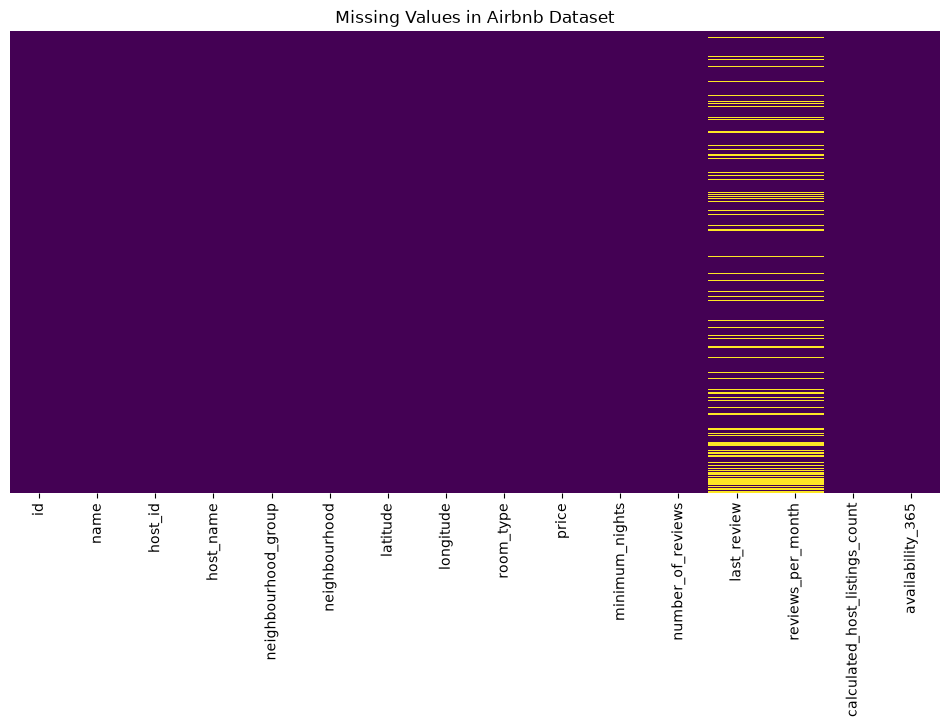

In [53]:
plt.figure(figsize=(12, 6))

sns.heatmap(df.isnull(), 
            cbar=False, 
            yticklabels=False, 
            cmap="viridis")

plt.title("Missing Values in Airbnb Dataset")
plt.show()

In [54]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

print(missing_percentage[missing_percentage > 0])

name                  0.032723
host_name             0.042949
last_review          20.558339
reviews_per_month    20.558339
dtype: float64


In [55]:
# Create a copy of original dataset
df_clean = df.copy()

# Fill missing names
df_clean["name"] = df_clean["name"].fillna("Unknown")

# Fill missing host names
df_clean["host_name"] = df_clean["host_name"].fillna("Unknown")

# Convert last_review into datetime format
df_clean["last_review"] = pd.to_datetime(
    df_clean["last_review"], errors="coerce"
)

print("Basic cleaning completed!")

Basic cleaning completed!


In [56]:
print("Missing Values After Cleaning:")
print(df_clean.isnull().sum())

Missing Values After Cleaning:
id                                    0
name                                  0
host_id                               0
host_name                             0
neighbourhood_group                   0
neighbourhood                         0
latitude                              0
longitude                             0
room_type                             0
price                                 0
minimum_nights                        0
number_of_reviews                     0
last_review                       10052
reviews_per_month                 10052
calculated_host_listings_count        0
availability_365                      0
dtype: int64


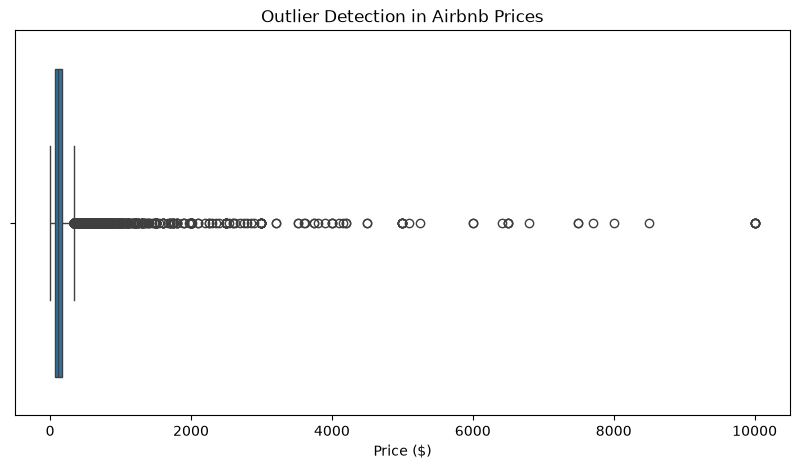

In [57]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=df_clean["price"])

plt.title("Outlier Detection in Airbnb Prices")
plt.xlabel("Price ($)")
plt.show()

In [58]:
Q1 = df_clean["price"].quantile(0.25)
Q3 = df_clean["price"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = df_clean[
    (df_clean["price"] < lower_limit) |
    (df_clean["price"] > upper_limit)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)
print("Total Price Outliers:", len(outliers))

Q1: 69.0
Q3: 175.0
IQR: 106.0
Lower Limit: -90.0
Upper Limit: 334.0
Total Price Outliers: 2972


In [59]:
print("Zero Prices:", (df_clean["price"] == 0).sum())

print("Negative Prices:", (df_clean["price"] < 0).sum())

print("\nHighest 10 Prices:")
print(df_clean["price"].nlargest(10))

Zero Prices: 11
Negative Prices: 0

Highest 10 Prices:
9151     10000
17692    10000
29238    10000
6530      9999
12342     9999
40433     9999
30268     8500
4377      8000
29662     7703
42523     7500
Name: price, dtype: int64


In [60]:
zero_price = df_clean[df_clean["price"] == 0]

print("Zero Price Records:")
display(
    zero_price[
        ["name", "host_name", "neighbourhood_group",
         "neighbourhood", "room_type", "price"]
    ]
)

Zero Price Records:


,name,host_name,neighbourhood_group,neighbourhood,room_type,price
23161,"Huge Brooklyn Brownstone Living, Close to it all.",Kimberly,Brooklyn,Bedford-Stuyvesant,Private room,0
25433,★Hostel Style Room | Ideal Traveling Buddies★,Anisha,Bronx,East Morrisania,Private room,0
25634,"MARTIAL LOFT 3: REDEMPTION (upstairs, 2nd room)",Martial Loft,Brooklyn,Bushwick,Private room,0
25753,"Sunny, Quiet Room in Greenpoint",Lauren,Brooklyn,Greenpoint,Private room,0
25778,Modern apartment in the heart of Williamsburg,Aymeric,Brooklyn,Williamsburg,Entire home/apt,0
25794,Spacious comfortable master bedroom with nice ...,Adeyemi,Brooklyn,Bedford-Stuyvesant,Private room,0
25795,Contemporary bedroom in brownstone with nice view,Adeyemi,Brooklyn,Bedford-Stuyvesant,Private room,0
25796,Cozy yet spacious private brownstone bedroom,Adeyemi,Brooklyn,Bedford-Stuyvesant,Private room,0
26259,the best you can find,Qiuchi,Manhattan,Murray Hill,Entire home/apt,0
26841,Coliving in Brooklyn! Modern design / Shared room,Sergii,Brooklyn,Bushwick,Shared room,0


In [61]:
df_clean["price"].describe()

count    48895.000000
mean       152.720687
std        240.154170
min          0.000000
25%         69.000000
50%        106.000000
75%        175.000000
max      10000.000000
Name: price, dtype: float64

In [62]:
# Remove listings with zero price
df_clean = df_clean[df_clean["price"] > 0].copy()

print("Cleaning completed!")
print("Original rows:", len(df))
print("Rows after removing zero prices:", len(df_clean))
print("Removed rows:", len(df) - len(df_clean))

Cleaning completed!
Original rows: 48895
Rows after removing zero prices: 48884
Removed rows: 11


In [63]:
print("Listings with zero reviews:",
      (df_clean["number_of_reviews"] == 0).sum())

print("\nMissing reviews_per_month with zero reviews:")
print(
    ((df_clean["number_of_reviews"] == 0) &
     (df_clean["reviews_per_month"].isnull())).sum()
)

print("\nMissing last_review with zero reviews:")
print(
    ((df_clean["number_of_reviews"] == 0) &
     (df_clean["last_review"].isnull())).sum()
)

Listings with zero reviews: 10051

Missing reviews_per_month with zero reviews:
10051

Missing last_review with zero reviews:
10051


In [64]:
print("FINAL DATASET VALIDATION")

print("\nDataset Shape:")
print(df_clean.shape)

print("\nDuplicate Rows:")
print(df_clean.duplicated().sum())

print("\nMissing Values:")
print(df_clean.isnull().sum())

print("\nZero Prices:")
print((df_clean["price"] == 0).sum())

print("\nData Types:")
print(df_clean.dtypes)

FINAL DATASET VALIDATION

Dataset Shape:
(48884, 16)

Duplicate Rows:
0

Missing Values:
id                                    0
name                                  0
host_id                               0
host_name                             0
neighbourhood_group                   0
neighbourhood                         0
latitude                              0
longitude                             0
room_type                             0
price                                 0
minimum_nights                        0
number_of_reviews                     0
last_review                       10051
reviews_per_month                 10051
calculated_host_listings_count        0
availability_365                      0
dtype: int64

Zero Prices:
0

Data Types:
id                                         int64
name                                         str
host_id                                    int64
host_name                                    str
neighbourhood_group              

In [65]:
import os

os.makedirs("../output", exist_ok=True)

df_clean.to_csv(
    "../output/cleaned_airbnb_data.csv",
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [66]:
comparison = pd.DataFrame({
    "Metric": [
        "Total Rows",
        "Total Columns",
        "Duplicate Rows",
        "Zero Price Records",
        "Missing Names",
        "Missing Host Names"
    ],
    "Before Cleaning": [
        len(df),
        df.shape[1],
        df.duplicated().sum(),
        (df["price"] == 0).sum(),
        df["name"].isnull().sum(),
        df["host_name"].isnull().sum()
    ],
    "After Cleaning": [
        len(df_clean),
        df_clean.shape[1],
        df_clean.duplicated().sum(),
        (df_clean["price"] == 0).sum(),
        df_clean["name"].isnull().sum(),
        df_clean["host_name"].isnull().sum()
    ]
})

display(comparison)

,Metric,Before Cleaning,After Cleaning
0,Total Rows,48895,48884
1,Total Columns,16,16
2,Duplicate Rows,0,0
3,Zero Price Records,11,0
4,Missing Names,16,0
5,Missing Host Names,21,0


In [67]:
import pandas as pd

df = pd.read_csv("../dataset/AB_NYC_2019.csv")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset Shape: (48895, 16)


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0
